# Análise de Viés Algorítmico em Seleção de Candidatos (XAI)
### Etapa 5: Explicabilidade Local com LIME

O LIME explica uma decisão individual por vez. Aqui comparamos pares de candidatos comparáveis (mesmo cargo, mesma idade, um homem e uma mulher) para ver se o gênero é decisivo no resultado.


## 1. Carregar modelo e dados

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import os
from lime.lime_tabular import LimeTabularExplainer

PASTA_DADOS = 'dados'

modelo = joblib.load(os.path.join(PASTA_DADOS, 'modelo_random_forest.pkl'))
X_train = pd.read_csv(os.path.join(PASTA_DADOS, 'X_train.csv'), index_col=0).astype(float)
X_test = pd.read_csv(os.path.join(PASTA_DADOS, 'X_test.csv'), index_col=0).astype(float)
df = pd.read_csv(os.path.join(PASTA_DADOS, 'recruitment_data_fixed.csv'))

print('X_train:', X_train.shape, '| X_test:', X_test.shape)

X_train: (8000, 54) | X_test: (2000, 54)


## 2. Montar pares comparáveis

Para cada combinação de cargo + idade, é procurado no banco de dados de teste um homem e uma mulher. Assim, a única diferença relevante entre os dois é o gênero.

In [2]:
teste = df.loc[X_test.index, ['Gender', 'Age', 'Job Roles']].copy()
teste['prob_aprovacao'] = modelo.predict_proba(X_test)[:, 1]

pares = []
for (cargo, idade), grupo in teste.groupby(['Job Roles', 'Age']):
    homens = grupo[grupo['Gender'] == 'Male']
    mulheres = grupo[grupo['Gender'] == 'Female']
    if len(homens) and len(mulheres):
        pares.append({
            'idx_homem': homens.index[0], 'idx_mulher': mulheres.index[0],
            'cargo': cargo, 'idade': idade,
            'prob_homem': homens['prob_aprovacao'].iloc[0],
            'prob_mulher': mulheres['prob_aprovacao'].iloc[0],
        })

pares = pd.DataFrame(pares)
pares['diferenca'] = pares['prob_homem'] - pares['prob_mulher']

print('Pares encontrados:', len(pares))
print('Diferença média de probabilidade (homem - mulher):', round(pares['diferenca'].mean(), 3))
print('% de pares em que o homem tem probabilidade maior:', round((pares['diferenca'] > 0).mean() * 100, 1))

Pares encontrados: 338
Diferença média de probabilidade (homem - mulher): 0.205
% de pares em que o homem tem probabilidade maior: 76.9


## 3. Criar o explicador LIME

In [3]:
# Todas as colunas, exceto Age, são binárias (0/1) -> tratadas como categóricas
idx_categoricas = [i for i, col in enumerate(X_train.columns) if col != 'Age']

explicador = LimeTabularExplainer(
    X_train.values,
    feature_names=list(X_train.columns),
    class_names=['Não aprovado', 'Aprovado'],
    categorical_features=idx_categoricas,
    mode='classification',
    random_state=42
)

## 4. Explicar um par (caso de maior diferença)

Valores positivos empurram para **Aprovado**, negativos para **Não aprovado**. 

Job Roles_Legal Consultant (consultor legal) é um cargo atípico no banco de dados, ele aparece tão alto pois quase ninguém é aprovado nele.

Caso: Financial Analyst, 31 anos

Homem — probabilidade de aprovação: 0.722
   Job Roles_Legal Consultant=0                       +0.240
   Gender_Male=1                                      +0.214
   Job Roles_Psychologist=0                           -0.100
   Job Roles_Nurse=0                                  +0.051
   Job Roles_Graphic Designer=0                       -0.040
   Job Roles_Customer Service Representative=0        -0.037
   Job Roles_Physician=0                              +0.034
   Job Roles_UX Designer=0                            +0.034


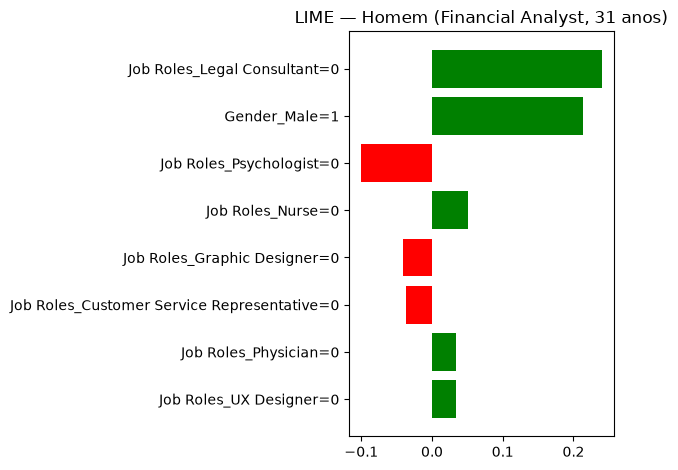


Mulher — probabilidade de aprovação: 0.284
   Job Roles_Legal Consultant=0                       +0.226
   Gender_Male=0                                      -0.210
   Job Roles_Psychologist=0                           -0.072
   Job Roles_HR Specialist=0                          +0.057
   Job Roles_Customer Service Representative=0        -0.048
   Job Roles_Graphic Designer=0                       -0.047
   Job Roles_Environmental Scientist=0                +0.032
   Job Roles_UX Designer=0                            +0.032


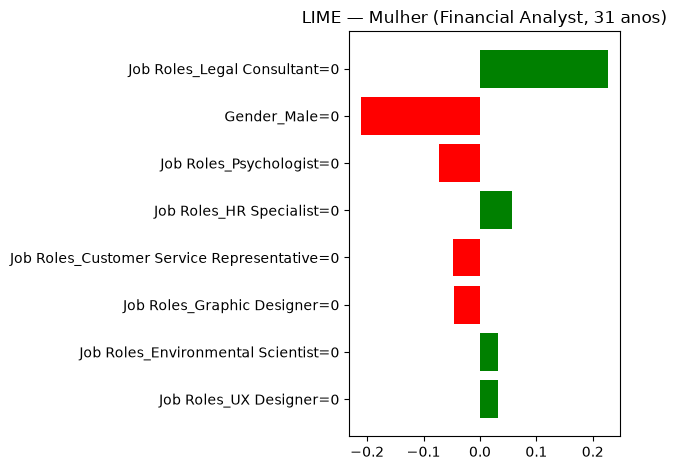

In [4]:
caso = pares.sort_values('diferenca', ascending=False).iloc[0]
print(f"Caso: {caso['cargo']}, {int(caso['idade'])} anos")

for nome, idx in [('Homem', int(caso['idx_homem'])), ('Mulher', int(caso['idx_mulher']))]:
    exp = explicador.explain_instance(
        X_test.loc[idx].values, modelo.predict_proba,
        num_features=8, num_samples=5000
    )
    prob = modelo.predict_proba(X_test.loc[[idx]].values)[0, 1]
    print(f'\n{nome} — probabilidade de aprovação: {prob:.3f}')
    for variavel, peso in exp.as_list():
        print(f'   {variavel:50s} {peso:+.3f}')

    fig = exp.as_pyplot_figure()
    plt.title(f'LIME — {nome} ({caso["cargo"]}, {int(caso["idade"])} anos)')
    plt.tight_layout()
    plt.savefig(os.path.join(PASTA_DADOS, f'lime_{nome.lower()}.png'), dpi=150, bbox_inches='tight')
    plt.show()

## 5. Teste de troca de gênero

Mantemos tudo igual em cada candidato e trocamos apenas o gênero, medindo quanto a probabilidade de aprovação muda.

In [5]:
X_trocado = X_test.copy()
X_trocado['Gender_Male'] = 1 - X_trocado['Gender_Male']

variacao = modelo.predict_proba(X_trocado)[:, 1] - modelo.predict_proba(X_test)[:, 1]
eh_homem = X_test['Gender_Male'].values == 1

print('Mudança média na probabilidade de aprovação ao trocar o gênero:')
print(f'  mulheres tratadas como homens: {variacao[~eh_homem].mean():+.3f}')
print(f'  homens tratados como mulheres: {variacao[eh_homem].mean():+.3f}')

Mudança média na probabilidade de aprovação ao trocar o gênero:
  mulheres tratadas como homens: +0.207
  homens tratados como mulheres: -0.196
